# 8주차 실습 — 파이프라인 v2: 모듈형 vs E2E · 멀티태스크 · 시간 정보 · 명령 조건부(CIL)
**AI Application · 스마트모빌리티학과 · 2026-10-21**

| 셀 | 내용 |
|---|---|
| 0-1 | 이 머신의 속도 측정 → 예상 실행 시간, FAST 자동 설정 |
| 1 | 모듈형 정책(도로 마스크 → 중심 추정 → PD) 만들기 + 인터페이스 보정 |
| 2 | 비교표 — 모듈형 vs E2E, 조건 5개 (기본 / 외란 1.2× / 스타일 / 노이즈 / 미공개) |
| 3 | 멀티태스크 — 조향 + 속도, λ 세 값 |
| 4 | 시간 정보 — 프레임 스택 vs 이전 조향 입력(인과 혼동) vs 출력 필터 |
| 5 | CIL — 명령(왼쪽/중앙/오른쪽) 조건부: 명령 없음 vs concat vs 분기 헤드 |
| 6 | 종합 비교표 CSV + 리포트 템플릿 |

**준비물**: `tinytrack.py`, Drive 의 `week07/my_policy_v2.pt`·`my_dataset_v2.npz` (없으면 v1 → 없으면 즉석 생성, `models/base_pilotnet.pt` 필요). CPU 로 전체 7~9분.

**약어**: E2E = End-to-End · CIL = Conditional Imitation Learning(명령 조건부 모방학습, Codevilla 외 ICRA 2018, arXiv:1710.02410) · PD = 비례·미분 제어 · MAE = 평균절대오차 · λ = 멀티태스크 손실 가중치 · 프레임 스택 = 최근 몇 프레임을 쌓아 입력 · CSV = 쉼표 구분 표

In [1]:
# ============ 0. 준비 (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json
for pkg in ["onnx", "onnxruntime", "pandas"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
import numpy as np, matplotlib.pyplot as plt, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
try:
    import tinytrack as tt
except ImportError:
    from google.colab import files
    print("tinytrack.py 를 업로드하세요"); files.upload(); import tinytrack as tt
try:
    from google.colab import drive
    drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive/AIApp")
except Exception:
    ROOT = Path("./outputs")
SAVE_DIR = ROOT / "week08"; SAVE_DIR.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)
H, W = tt.H, tt.W

# --- 데이터: v2 (7주차 집계) → v1 → 즉석
for cand in [ROOT / "week07" / "my_dataset_v2.npz", ROOT / "week05" / "my_dataset_v1.npz"]:
    if cand.exists():
        D = tt.load_npz(cand); print("데이터 로드:", cand.name, len(D["steers"])); break
else:
    print("데이터가 없어 즉석 생성합니다 (약 20초)")
    D = tt.rebalance(tt.merge(*[tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 500, seed=10 * ord(n) + k, noise_inject=ni)
                                for n in "ABC" for k, ni in enumerate([0.0, 0.4, 0.8])]))
D = {k: D[k] for k in ("images", "steers", "states", "run_id")}
tr, va = tt.split_by_run(D, 0.2, seed=0)

# --- E2E 정책: v2 → v1 → 베이스에서 즉석 미세조정
MODELS = Path("models") if Path("models/base_pilotnet.pt").exists() else Path(".")
for cand in [ROOT / "week07" / "my_policy_v2.pt", ROOT / "week06" / "my_policy_v1.pt"]:
    if cand.exists():
        e2e = tt.load_model(cand); print("E2E 정책 로드:", cand.name); break
else:
    if not (MODELS / "base_pilotnet.pt").exists():
        from google.colab import files
        print("base_pilotnet.pt 를 업로드하세요"); files.upload()
    print("정책이 없어 베이스에서 3에폭 미세조정합니다 (약 1분)")
    e2e = tt.load_model(MODELS / "base_pilotnet.pt")
    tt.train_bc(e2e, tr, va, epochs=3, lr=3e-4, augment=tt.make_augment(seed=0), verbose=False)
E2E_PT = SAVE_DIR / "e2e_policy.pt"; torch.save(e2e.state_dict(), E2E_PT)
pol_e2e = tt.TorchPolicy(e2e)

PUBLIC, HIDDEN = ["A", "B", "C"], [tt.Track.random(101), tt.Track.random(202)]
NORMAL, HARD = tt.DEFAULT_DISTURB, dict(every=50, d=0.42, psi=0.36)
STYLE_DARK = dict(road=(0.26, 0.27, 0.30), lane=(0.62, 0.62, 0.62))     # 노면·차선을 어둡게 (색 기준 마스크가 깨진다)

def batches(ds, idx, bs=64):                                            # uint8 → float 은 배치마다 (메모리 절약)
    for s in range(0, len(idx), bs):
        j = idx[s:s + bs]
        x = torch.from_numpy(np.concatenate([tt.preprocess(im) for im in ds["images"][j]]))
        yield j, x

def steer_mae(model_fn, ds, n=400):
    idx = np.arange(min(n, len(ds["steers"])))
    with torch.no_grad():
        pred = np.concatenate([model_fn(x).numpy().ravel() for _, x in batches(ds, idx, 128)])
    return float(np.abs(pred - ds["steers"][idx]).mean())

print("tinytrack", tt.__version__, "| 학습", len(tr["steers"]), "검증", len(va["steers"]), "| 저장:", SAVE_DIR)

tinytrack.py 를 업로드하세요


Saving tinytrack.py to tinytrack.py
Mounted at /content/drive
데이터 로드: my_dataset_v2.npz 4150
E2E 정책 로드: my_policy_v2.pt
tinytrack 0.3.1 | 학습 3007 검증 1143 | 저장: /content/drive/MyDrive/AIApp/week08


### 0-1. 이 머신의 속도 측정 (5초) → 예상 실행 시간과 `FAST` 자동 설정
느린 머신(Colab 무료 CPU 등)이면 `FAST=True` 가 되어 학습 프레임·에폭을 줄입니다. 결과의 방향은 같고 숫자만 조금 거칩니다. 직접 바꾸려면 아래 셀에서 `FAST = True/False` 로 덮어쓰세요.

In [2]:
import time as _t
_t0 = _t.time(); [tt.render(0.1, 0.05, 0.1) for _ in range(300)]; _tr = _t.time() - _t0
_m = tt.make_model().eval(); _x = torch.zeros(64, 3, tt.H, tt.W)
with torch.no_grad():
    _m(_x); _t0 = _t.time(); [_m(_x) for _ in range(10)]; _tf = _t.time() - _t0
REF_RENDER, REF_FWD, REF_MIN = 0.195, 0.318, 11          # 제작 PC 기준값 (렌더 300장 s, 순전파 10회 s, 전체 실행 분)
ratio = 0.5 * (_tr / REF_RENDER) + 0.5 * (_tf / REF_FWD)
FAST = os.environ.get("NB_FAST") == "1" or ratio > 1.8
print(f"렌더 300장 {_tr:.2f}s · 순전파 10회 {_tf:.2f}s → 제작 PC 대비 {ratio:.1f}배 → 예상 전체 실행 약 {REF_MIN * ratio * (0.6 if FAST else 1.0):.0f}분 | FAST = {FAST}")

렌더 300장 0.31s · 순전파 10회 1.99s → 제작 PC 대비 3.9배 → 예상 전체 실행 약 26분 | FAST = True


## 1. 모듈형 정책 — 도로 마스크 → (d̂, ψ̂) → PD 제어
관측은 E2E 와 똑같이 **이미지만**. 인지 = 도로색 픽셀 마스크, 표현 = 가까운 행·먼 행의 도로 중심 px → (d̂, ψ̂), 제어 = PD.
픽셀 → 미터 변환은 카메라 기하를 외우는 대신 **합성 렌더로 보정**합니다 (알려진 (d, ψ) 로 200장 렌더 → 최소제곱). 차가 가장자리로 밀려 도로가 화면 밖으로 잘리면 행별 도로 폭으로 보정합니다.

In [3]:
ROAD = np.array(tt.DEFAULT_STYLE["road"], dtype=np.float32)
ROWS = np.arange(tt.Y_HORIZON + 4, H)                                     # 도로가 보이는 행

def blur3(f):                                                              # 3×3 평균 — 픽셀 노이즈 완화 (가장자리는 복제)
    p = np.pad(f, ((1, 1), (1, 1), (0, 0)), mode="edge")
    return sum(p[i:i + H, j:j + W] for i in range(3) for j in range(3)) / 9.0

def road_mask(img, tol=0.12):                                              # 인지: 도로색 픽셀 (색 허용오차 — 사람이 정한 상수)
    return np.abs(blur3(img.astype(np.float32) / 255) - ROAD).max(axis=2) < tol

# 행별 도로 폭(px) — 정중앙(d=0, ψ=0) 렌더 한 장으로 보정 (카메라 기하는 몰라도 됨)
_m0 = road_mask(tt.render(0.0, 0.0, 0.0))
ROAD_W_PX = {r: (np.where(_m0[r])[0].max() - np.where(_m0[r])[0].min()) for r in ROWS if _m0[r].sum() > 5}
ROW_NEAR, ROW_FAR = H - 3, H - 32                                          # 가까운 행(≈0.6 m), 먼 행(≈1.3 m)

def road_center(mask, row):                                                # 표현: 한 행의 도로 중심 px (화면에 잘리면 폭으로 보정)
    xs = np.where(mask[row])[0]
    if len(xs) < 5: return np.nan
    left, right = np.percentile(xs, 3), np.percentile(xs, 97)
    wpx = ROAD_W_PX.get(row, right - left)
    if left <= 1 and right < W - 2:  return right - wpx / 2               # 왼쪽이 잘림
    if right >= W - 2 and left > 1:  return left + wpx / 2                # 오른쪽이 잘림
    return (left + right) / 2

# --- 보정: (near, far) 픽셀 → (d, ψ) 선형 회귀 (알려진 상태로 200장 렌더)
rng = np.random.RandomState(0); feats, targets = [], []
for _ in range(200):
    d0, p0 = rng.uniform(-0.4, 0.4), rng.uniform(-0.4, 0.4)
    m = road_mask(tt.render(d0, p0, 0.0)); n_, f_ = road_center(m, ROW_NEAR), road_center(m, ROW_FAR)
    if np.isfinite(n_) and np.isfinite(f_):
        feats.append([n_ - W / 2, f_ - W / 2, 1.0]); targets.append([d0, p0])
A, _, _, _ = np.linalg.lstsq(np.array(feats), np.array(targets), rcond=None)     # (3,2)
print("보정 계수 (near, far, 1) → d:", A[:, 0].round(4), "| → ψ:", A[:, 1].round(4), f"| 표본 {len(feats)}")

class ModularPolicy:
    def __init__(self, kd=2.0, kpsi=1.5, tol=0.12):
        self.kd, self.kpsi, self.tol, self.last_d = kd, kpsi, tol, 0.0
    def estimate(self, obs):
        m = road_mask(obs, self.tol); n_, f_ = road_center(m, ROW_NEAR), road_center(m, ROW_FAR)
        if not np.isfinite(n_):
            return None                                                    # 인지 실패 (가까운 행에 도로가 없음)
        if not np.isfinite(f_):
            f_ = n_                                                        # 먼 행이 안 보이면 헤딩 0 으로 가정
        d_hat, psi_hat = np.array([n_ - W / 2, f_ - W / 2, 1.0]) @ A
        return float(d_hat), float(psi_hat)
    def __call__(self, obs, state=None):
        est = self.estimate(obs)
        if est is None:                                                    # 인지 실패: 마지막으로 도로가 보였던 쪽으로 최대 조향 (규칙 = 안전 장치)
            return float(-np.sign(self.last_d)) if self.last_d != 0 else 0.0
        d_hat, psi_hat = est; self.last_d = d_hat
        return float(np.clip(-(self.kd * d_hat + self.kpsi * psi_hat), -1, 1))

pol_mod = ModularPolicy()
errs = np.array([np.subtract(pol_mod.estimate(im) or (np.nan, np.nan), st[:2]) for im, st in zip(va["images"][:300], va["states"][:300])])
print(f"d̂ 오차 MAE {np.nanmean(np.abs(errs[:,0])):.3f} m | ψ̂ 오차 MAE {np.nanmean(np.abs(errs[:,1])):.3f} rad | 인지 실패 {np.isnan(errs[:,0]).mean():.1%}  (커브에서는 먼 행이 곡률 때문에 치우침 → ψ̂ 편향 = 암묵적 피드포워드)")
for kd in (1.0, 2.0, 3.0):
    r = tt.evaluate(ModularPolicy(kd=kd), PUBLIC)
    print(f"kd={kd}: score {r['score']:.1f} | completion {r['completion']:.2f} | mean|d| {r['mean_abs_d']:.3f}")

보정 계수 (near, far, 1) → d: [-0.0137  0.0054 -0.0017] | → ψ: [ 0.0081 -0.0098 -0.0006] | 표본 200
d̂ 오차 MAE 0.132 m | ψ̂ 오차 MAE 0.191 rad | 인지 실패 0.0%  (커브에서는 먼 행이 곡률 때문에 치우침 → ψ̂ 편향 = 암묵적 피드포워드)
kd=1.0: score 46.9 | completion 0.83 | mean|d| 0.150
kd=2.0: score 88.4 | completion 1.00 | mean|d| 0.116
kd=3.0: score 88.4 | completion 1.00 | mean|d| 0.116


## 2. 비교표 — 모듈형 vs E2E, 조건 5개
같은 관측·같은 프로토콜. 조건: 기본(외란 1.0×) / 외란 1.2× / 스타일 변경(노면·차선 어둡게) / 이미지 노이즈 / 미공개 트랙.
**예상**(덱 PART 2)과 다른 칸을 찾으세요 — 그 칸이 리포트의 해석이 됩니다.

           기본  외란1.2x   스타일   노이즈   미공개
modular  88.4    32.0   0.9  87.5  88.5
e2e      86.7    69.9  88.0  86.7  87.0 
(190s)


/tmp/ipykernel_749/4245954463.py:14: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "compare_conditions.png", dpi=120); plt.show()
/tmp/ipykernel_749/4245954463.py:14: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "compare_conditions.png", dpi=120); plt.show()
/tmp/ipykernel_749/4245954463.py:14: UserWarning: Glyph 50808 (\N{HANGUL SYLLABLE OE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "compare_conditions.png", dpi=120); plt.show()
/tmp/ipykernel_749/4245954463.py:14: UserWarning: Glyph 46976 (\N{HANGUL SYLLABLE RAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "compare_conditions.png", dpi=120); plt.show()
/tmp/ipykernel_749/4245954463.py:14: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); pl

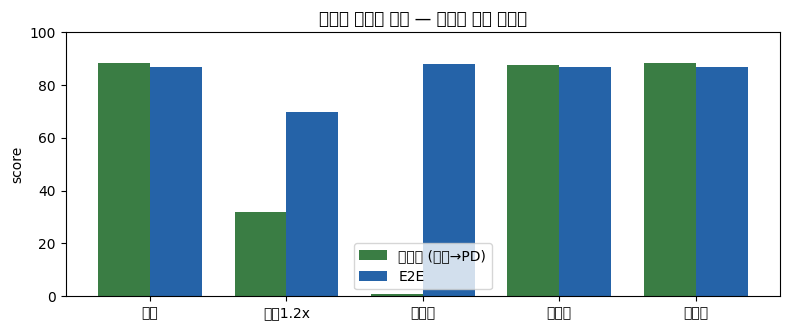

/tmp/ipykernel_749/4245954463.py:22: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_749/4245954463.py:22: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_749/4245954463.py:22: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_749/4245954463.py:22: UserWarning: Glyph 53440 (\N{HANGUL SYLLABLE TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_749/4245954463.py:22: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_749/4245954463.py:22: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_749/4245954463.py:22: UserWarning: Glyph 44221 (\N{HANGU

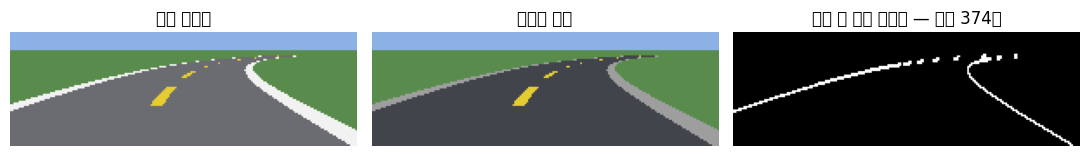

In [4]:
CONDS = {"기본": dict(tracks=PUBLIC), "외란1.2x": dict(tracks=PUBLIC, disturb=HARD), "스타일": dict(tracks=PUBLIC, style=STYLE_DARK),
         "노이즈": dict(tracks=PUBLIC, noise=0.08), "미공개": dict(tracks=HIDDEN)}

def eval_conditions(pol, conds=CONDS):
    return {name: tt.evaluate(pol, seed=0, **kw)["score"] for name, kw in conds.items()}

t0 = time.time()
table = {"modular": eval_conditions(ModularPolicy()), "e2e": eval_conditions(pol_e2e)}
cmp_df = pd.DataFrame(table).T.round(1); print(cmp_df.to_string(), f"\n({time.time()-t0:.0f}s)")

fig, ax = plt.subplots(figsize=(8, 3.4)); x = np.arange(len(CONDS)); w = 0.38
ax.bar(x - w/2, cmp_df.loc["modular"], w, label="모듈형 (차선→PD)", color="#3A7D44"); ax.bar(x + w/2, cmp_df.loc["e2e"], w, label="E2E", color="#2563A8")
ax.set_xticks(x); ax.set_xticklabels(CONDS.keys()); ax.set_ylim(0, 100); ax.set_ylabel("score"); ax.legend(); ax.set_title("조건별 폐루프 점수 — 어디서 누가 이기나")
plt.tight_layout(); plt.savefig(SAVE_DIR / "compare_conditions.png", dpi=120); plt.show()

# 스타일 조건에서 모듈형이 왜 무너지는지 — 마스크를 눈으로
img_dark = tt.render(0.1, 0.05, 0.1, style=STYLE_DARK)
fig, ax = plt.subplots(1, 3, figsize=(11, 2.4))
ax[0].imshow(tt.render(0.1, 0.05, 0.1)); ax[0].set_title("기본 스타일"); ax[1].imshow(img_dark); ax[1].set_title("스타일 변경")
ax[2].imshow(road_mask(img_dark), cmap="gray"); ax[2].set_title(f"변경 후 도로 마스크 — 픽셀 {road_mask(img_dark).sum()}개")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3. 멀티태스크 — 조향 + 속도
속도 라벨은 곡률에서: `v = 1 − 0.5·|κ|/κ_max` (직선 1.0, 최대 곡률 0.5). 공유 트렁크 + 헤드 2개, 손실 `L = L_steer + λ·L_speed`.
단일(조향) 과 멀티 λ ∈ {0.1, 0.5, 1.0} 의 **조향 MAE / 속도 MAE / 폐루프**를 비교합니다 (각 2에폭, 3,000 프레임).

λ=0.0: 조향 MAE 0.0527 | 속도 MAE 0.6165 | 폐루프 88.2  (56s)
λ=0.5: 조향 MAE 0.0616 | 속도 MAE 0.1878 | 폐루프 85.7  (101s)

   model  steer_mae  speed_mae  closed_loop
  단일(조향)     0.0527        NaN      88.2348
멀티 λ=0.5     0.0616     0.1878      85.6536


/tmp/ipykernel_749/3978958567.py:53: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "speed_profile.png", dpi=120); plt.show()
/tmp/ipykernel_749/3978958567.py:53: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "speed_profile.png", dpi=120); plt.show()
/tmp/ipykernel_749/3978958567.py:53: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "speed_profile.png", dpi=120); plt.show()
/tmp/ipykernel_749/3978958567.py:53: UserWarning: Glyph 49549 (\N{HANGUL SYLLABLE SOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DIR / "speed_profile.png", dpi=120); plt.show()
/tmp/ipykernel_749/3978958567.py:53: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.savefig(SAVE_DI

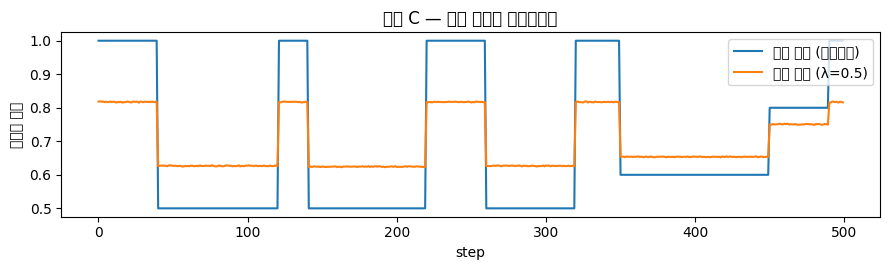

In [5]:
def speed_label(states):
    return (1.0 - 0.5 * np.abs(states[:, 2]) / tt.KAPPA_MAX).astype(np.float32)

class MultiTaskNet(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.features = base.features
        self.trunk = nn.Sequential(nn.Flatten(), nn.Linear(64 * 18, 100), nn.ReLU())
        self.steer_head, self.speed_head = nn.Linear(100, 1), nn.Linear(100, 1)
    def forward(self, x):
        h = self.trunk(self.features(x)); return self.steer_head(h), self.speed_head(h)

def train_multitask(lam, epochs=2, n=3000, seed=0):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    net = MultiTaskNet(tt.load_model(E2E_PT)); opt = torch.optim.Adam(net.parameters(), 3e-4)
    idx_all = rng.choice(len(tr["steers"]), min(n, len(tr["steers"])), replace=False)
    ys, yv = torch.from_numpy(tr["steers"]).unsqueeze(1), torch.from_numpy(speed_label(tr["states"])).unsqueeze(1)
    for ep in range(epochs):
        net.train(); rng.shuffle(idx_all)
        for j, x in batches(tr, idx_all):
            s, v = net(x)
            loss = F.mse_loss(s, ys[j]) + (lam * F.mse_loss(v, yv[j]) if lam > 0 else 0.0)
            opt.zero_grad(); loss.backward(); opt.step()
    net.eval()
    idx = np.arange(min(400, len(va["steers"])))
    with torch.no_grad():
        outs = [net(x) for _, x in batches(va, idx, 128)]
    ps, pv = np.concatenate([o[0].numpy().ravel() for o in outs]), np.concatenate([o[1].numpy().ravel() for o in outs])
    return net, float(np.abs(ps - va["steers"][idx]).mean()), float(np.abs(pv - speed_label(va["states"])[idx]).mean())

class HeadPolicy:                                   # 멀티태스크 네트워크의 조향 헤드만 폐루프에
    def __init__(self, net): self.net = net.eval()
    def __call__(self, obs, state=None):
        with torch.no_grad(): return float(self.net(torch.from_numpy(tt.preprocess(obs)))[0].item())

N_TRAIN = 1500 if FAST else 3000                                   # FAST: 학습 프레임 절반
rows = []; t0 = time.time(); nets = {}
for lam in ((0.0, 0.5) if FAST else (0.0, 0.1, 0.5, 1.0)):
    net, m_s, m_v = train_multitask(lam, n=N_TRAIN)
    cl = tt.evaluate(HeadPolicy(net), PUBLIC)["score"]
    rows.append(dict(model="단일(조향)" if lam == 0 else f"멀티 λ={lam}", steer_mae=m_s, speed_mae=m_v if lam > 0 else np.nan, closed_loop=cl)); nets[lam] = net
    print(f"λ={lam}: 조향 MAE {m_s:.4f} | 속도 MAE {m_v:.4f} | 폐루프 {cl:.1f}  ({time.time()-t0:.0f}s)")
mt_df = pd.DataFrame(rows).round(4); print("\n" + mt_df.to_string(index=False))

# 속도 프로파일: 트랙 C 를 전문가로 한 바퀴 돌며 예측 속도 vs 라벨
env = tt.Env(tt.Track.preset("C"), seed=0); obs = env.reset(seed=0); pv, tv = [], []
net = nets[0.5].eval()
for t in range(500):
    with torch.no_grad(): pv.append(float(net(torch.from_numpy(tt.preprocess(obs)))[1].item()))
    tv.append(1.0 - 0.5 * abs(env.state[2]) / tt.KAPPA_MAX)
    obs, *_ = env.step(tt.ExpertPolicy()(obs, env.state))
plt.figure(figsize=(9, 2.8)); plt.plot(tv, label="속도 라벨 (곡률에서)"); plt.plot(pv, label="예측 속도 (λ=0.5)"); plt.xlabel("step"); plt.ylabel("정규화 속도"); plt.legend(); plt.title("트랙 C — 코너 앞에서 감속하는가")
plt.tight_layout(); plt.savefig(SAVE_DIR / "speed_profile.png", dpi=120); plt.show()

## 4. 시간 정보 — 프레임 스택 vs 이전 조향 입력 vs 출력 필터
- **프레임 스택**: 현재+직전 프레임 (관측만) → 공유 conv 를 두 번 태워 특징을 이어 붙임
- **이전 조향 입력**: 특징 + 직전 조향(행동). 오프라인은 좋아지기 쉽고, 폐루프에서는 자기 출력을 되먹임 → **인과 혼동**이 생길 수 있는 구조. (tinytrack 은 한 장의 관측이 상태를 거의 다 담고 있어 잘 안 무너집니다 — 실차처럼 과거 행동이 라벨을 거의 결정하는 데이터에서 위험. 결과가 어느 쪽이든 '읽는 법'대로 해석)
- **출력 필터**: 학습 없이 `steer = 0.7·now + 0.3·prev`
지표: 폐루프 score, mean|d|, **조향 저크**(연속 조향 차분의 표준편차 — 진동 지표).

In [6]:
def pair_prev(ds):                                   # run 안에서 i 와 i−1 짝짓기 (run 경계는 자기 자신)
    prev = np.arange(len(ds["steers"])) - 1
    prev[0] = 0; prev[ds["run_id"] != np.roll(ds["run_id"], 1)] = np.where(ds["run_id"] != np.roll(ds["run_id"], 1))[0]
    return prev

class TwoFrameNet(nn.Module):                        # 과거 '관측'
    def __init__(self, base):
        super().__init__(); self.features = base.features; self.flat = nn.Flatten()
        self.head = nn.Sequential(nn.Linear(2 * 64 * 18, 100), nn.ReLU(), nn.Linear(100, 1))
    def forward(self, x, xp):
        return self.head(torch.cat([self.flat(self.features(x)), self.flat(self.features(xp))], 1))

class PrevActionNet(nn.Module):                      # 과거 '행동' (인과 혼동 실험용)
    def __init__(self, base):
        super().__init__(); self.features = base.features; self.flat = nn.Flatten()
        self.head = nn.Sequential(nn.Linear(64 * 18 + 1, 100), nn.ReLU(), nn.Linear(100, 1))
    def forward(self, x, a_prev):
        return self.head(torch.cat([self.flat(self.features(x)), a_prev], 1))

def train_temporal(kind, epochs=2, n=3000, seed=0):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    net = (TwoFrameNet if kind == "stack" else PrevActionNet)(tt.load_model(E2E_PT)); opt = torch.optim.Adam(net.parameters(), 3e-4)
    prev = pair_prev(tr); ys = torch.from_numpy(tr["steers"]).unsqueeze(1)
    idx_all = rng.choice(len(tr["steers"]), min(n, len(tr["steers"])), replace=False)
    for ep in range(epochs):
        net.train(); rng.shuffle(idx_all)
        for j, x in batches(tr, idx_all):
            if kind == "stack":
                xp = torch.from_numpy(np.concatenate([tt.preprocess(im) for im in tr["images"][prev[j]]])); out = net(x, xp)
            else:
                out = net(x, ys[prev[j]])
            loss = F.mse_loss(out, ys[j]); opt.zero_grad(); loss.backward(); opt.step()
    net.eval(); prev_v = pair_prev(va); idx = np.arange(min(400, len(va["steers"]))); yv = torch.from_numpy(va["steers"]).unsqueeze(1)
    with torch.no_grad():
        if kind == "stack":
            pred = np.concatenate([net(x, torch.from_numpy(np.concatenate([tt.preprocess(im) for im in va["images"][prev_v[j]]]))).numpy().ravel() for j, x in batches(va, idx, 128)])
        else:
            pred = np.concatenate([net(x, yv[prev_v[j]]).numpy().ravel() for j, x in batches(va, idx, 128)])
    return net, float(np.abs(pred - va["steers"][idx]).mean())

class StackPolicy:
    def __init__(self, net): self.net, self.prev = net.eval(), None
    def __call__(self, obs, state=None):
        if self.prev is None: self.prev = obs
        with torch.no_grad():
            a = float(self.net(torch.from_numpy(tt.preprocess(obs)), torch.from_numpy(tt.preprocess(self.prev))).item())
        self.prev = obs; return a

class PrevActionPolicy:                              # 폐루프에서는 '자기가 낸 직전 조향'을 입력으로
    def __init__(self, net): self.net, self.a = net.eval(), 0.0
    def __call__(self, obs, state=None):
        with torch.no_grad():
            self.a = float(self.net(torch.from_numpy(tt.preprocess(obs)), torch.tensor([[self.a]], dtype=torch.float32)).item())
        return self.a

class FilterPolicy:
    def __init__(self, pol, alpha=0.7): self.pol, self.alpha, self.a = pol, alpha, 0.0
    def __call__(self, obs, state=None):
        self.a = self.alpha * self.pol(obs, state) + (1 - self.alpha) * self.a; return self.a

def rollout_metrics(make_pol, tracks=PUBLIC, disturb=NORMAL, seed=0):
    res = tt.evaluate(make_pol(), tracks, seed=seed, disturb=disturb); jerks = []
    for t in tracks:
        pol = make_pol(); env = tt.Env(tt.Track.preset(t), disturb=disturb, seed=seed); obs = env.reset(seed=seed); acts = []; done = False
        while not done:
            a = pol(obs, env.state); acts.append(a); obs, _, term, trunc, _ = env.step(a); done = term or trunc
        jerks.append(np.std(np.diff(acts)) if len(acts) > 2 else 0.0)
    return dict(score=res["score"], completion=res["completion"], mean_abs_d=res["mean_abs_d"], jerk=float(np.mean(jerks)))

t0 = time.time()
net_stack, mae_stack = train_temporal("stack", n=N_TRAIN); net_prev, mae_prev = train_temporal("prev", n=N_TRAIN)
mae_single = steer_mae(lambda x: e2e.eval()(x), va)
rows = []
for name, mae, mk in [("단일 프레임", mae_single, lambda: tt.TorchPolicy(e2e)),
                      ("프레임 스택(관측 2장)", mae_stack, lambda: StackPolicy(net_stack)),
                      ("이전 조향 입력(행동)", mae_prev, lambda: PrevActionPolicy(net_prev)),
                      ("단일 + 출력 필터 0.7", mae_single, lambda: FilterPolicy(tt.TorchPolicy(e2e), 0.7))]:
    m = rollout_metrics(mk); rows.append(dict(model=name, offline_mae=mae, **m))
tm_df = pd.DataFrame(rows).round(4); print(tm_df.to_string(index=False), f"\n({time.time()-t0:.0f}s)")
print("읽는 법: '이전 조향 입력' 이 오프라인은 좋은데 폐루프가 나쁘면 인과 혼동 (안 나타나면 관측이 충분한 것 — 구조적 위험은 그대로). 스택·필터는 jerk(진동)·mean|d| 가 줄어야 성공")

         model  offline_mae   score  completion  mean_abs_d   jerk
        단일 프레임       0.0270 86.7218         1.0      0.1328 0.0966
 프레임 스택(관측 2장)       0.0348 88.1620         1.0      0.1184 0.0685
  이전 조향 입력(행동)       0.0343 88.3449         1.0      0.1166 0.0866
단일 + 출력 필터 0.7       0.0270 86.7398         1.0      0.1326 0.0717 
(308s)
읽는 법: '이전 조향 입력' 이 오프라인은 좋은데 폐루프가 나쁘면 인과 혼동 (안 나타나면 관측이 충분한 것 — 구조적 위험은 그대로). 스택·필터는 jerk(진동)·mean|d| 가 줄어야 성공


## 5. CIL — 명령 조건부: 왼쪽 / 중앙 / 오른쪽 차로 유지
명령 c ∈ {0: 왼쪽(−0.25), 1: 중앙(0), 2: 오른쪽(+0.25)}. 오프셋 전문가로 명령별 데이터를 모으고 세 모델을 비교합니다.
- **명령 없음**: 같은 화면에 세 라벨이 섞여 평균(≈ 중앙)으로 뭉개짐
- **concat**: 특징 + one-hot → 명령이 무시되기 쉬움
- **분기 헤드**: 명령이 헤드를 선택 → 구조적으로 따름

명령 조건부 데이터 1800 프레임 (2s) | 명령별 mean d: {'왼쪽': -0.249, '중앙': 0.037, '오른쪽': 0.206}
 model 왼쪽(목표 -0.25) 중앙(목표 +0.00) 오른쪽(목표 +0.25)  명령 추종 오차  sec
 명령 없음       +0.085       +0.085        +0.085     0.195   35
concat       +0.009       +0.020        +0.111     0.140   40
 분기 헤드       -0.255       -0.013        +0.252     0.007   37


/tmp/ipykernel_749/2014652391.py:72: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.xlabel("step"); plt.ylabel("d (m)"); plt.legend(); plt.title("분기 헤드 CIL — 명령 전환 (왼쪽 → 중앙 → 오른쪽)"); plt.tight_layout(); plt.savefig(SAVE_DIR / "cil_switch.png", dpi=120); plt.show()
/tmp/ipykernel_749/2014652391.py:72: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.xlabel("step"); plt.ylabel("d (m)"); plt.legend(); plt.title("분기 헤드 CIL — 명령 전환 (왼쪽 → 중앙 → 오른쪽)"); plt.tight_layout(); plt.savefig(SAVE_DIR / "cil_switch.png", dpi=120); plt.show()
/tmp/ipykernel_749/2014652391.py:72: UserWarning: Glyph 54756 (\N{HANGUL SYLLABLE HE}) missing from font(s) DejaVu Sans.
  plt.xlabel("step"); plt.ylabel("d (m)"); plt.legend(); plt.title("분기 헤드 CIL — 명령 전환 (왼쪽 → 중앙 → 오른쪽)"); plt.tight_layout(); plt.savefig(SAVE_DIR / "cil_switch.png", dpi=120); plt.show()
/tmp/ipykernel_749/2014652391.py:72: UserWarning: Glyph 46300 (\N{HANGUL SY

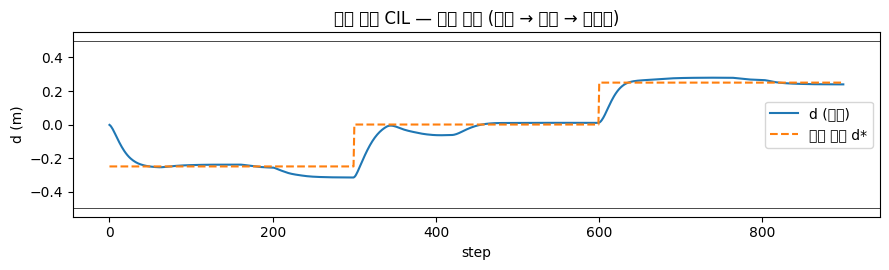

In [7]:
class OffsetExpert:
    def __init__(self, target): self.target = target
    def __call__(self, obs, state):
        return tt.expert_steer(state[0] - self.target, state[1], state[2])

COMMANDS = {0: -0.25, 1: 0.0, 2: 0.25}; NAMES = {0: "왼쪽", 1: "중앙", 2: "오른쪽"}
t0 = time.time(); parts = []
for c, tgt in COMMANDS.items():
    ex = OffsetExpert(tgt)
    ds = tt.collect(ex, tt.Track.preset("B"), 600, seed=100 + c, noise_inject=0.4, expert=ex)
    ds["command"] = np.full(len(ds["steers"]), c, dtype=np.int64); parts.append(ds)
C = {k: np.concatenate([p[k] for p in parts]) for k in ("images", "steers", "states", "command")}
print(f"명령 조건부 데이터 {len(C['steers'])} 프레임 ({time.time()-t0:.0f}s) | 명령별 mean d:", {NAMES[c]: round(float(C['states'][C['command']==c, 0].mean()), 3) for c in COMMANDS})

class NoCmdNet(nn.Module):
    def __init__(self, base):
        super().__init__(); self.features, self.head = base.features, nn.Sequential(nn.Flatten(), nn.Linear(64 * 18, 50), nn.ReLU(), nn.Linear(50, 1))
    def forward(self, x, cmd): return self.head(self.features(x))

class ConcatNet(nn.Module):
    def __init__(self, base, n_cmd=3):
        super().__init__(); self.features, self.flat = base.features, nn.Flatten()
        self.head = nn.Sequential(nn.Linear(64 * 18 + n_cmd, 50), nn.ReLU(), nn.Linear(50, 1)); self.n = n_cmd
    def forward(self, x, cmd):
        return self.head(torch.cat([self.flat(self.features(x)), F.one_hot(cmd, self.n).float()], 1))

class BranchNet(nn.Module):
    def __init__(self, base, n_cmd=3):
        super().__init__(); self.features, self.flat = base.features, nn.Flatten()
        self.heads = nn.ModuleList([nn.Sequential(nn.Linear(64 * 18, 50), nn.ReLU(), nn.Linear(50, 1)) for _ in range(n_cmd)])
    def forward(self, x, cmd):
        h = self.flat(self.features(x)); outs = torch.stack([hd(h) for hd in self.heads], 1)
        return outs[torch.arange(len(x)), cmd]

def train_cil(cls, epochs=3, seed=0):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    net = cls(tt.load_model(E2E_PT)); opt = torch.optim.Adam(net.parameters(), 3e-4)
    ys, cs = torch.from_numpy(C["steers"]).unsqueeze(1), torch.from_numpy(C["command"]); idx_all = np.arange(len(C["steers"]))
    for ep in range(epochs):
        net.train(); rng.shuffle(idx_all)
        for j, x in batches(C, idx_all):
            loss = F.mse_loss(net(x, cs[j]), ys[j]); opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

class CmdPolicy:
    def __init__(self, net, cmd): self.net, self.cmd = net, cmd
    def __call__(self, obs, state=None):
        with torch.no_grad(): return float(self.net(torch.from_numpy(tt.preprocess(obs)), torch.tensor([self.cmd])).item())

def mean_d(pol, steps=400, seed=0):
    env = tt.Env(tt.Track.preset("B"), seed=seed, max_steps=steps); obs = env.reset(seed=seed); ds_ = []
    for _ in range(steps):
        obs, _, term, trunc, info = env.step(pol(obs, env.state)); ds_.append(info["d"])
        if term or trunc: break
    return float(np.mean(ds_)), bool(term)

rows = []; nets_cil = {}
for name, cls in [("명령 없음", NoCmdNet), ("concat", ConcatNet), ("분기 헤드", BranchNet)]:
    t0 = time.time(); net = train_cil(cls, epochs=2 if FAST else 3); nets_cil[name] = net; row = dict(model=name)
    for c, tgt in COMMANDS.items():
        md_, off = mean_d(CmdPolicy(net, c)); row[f"{NAMES[c]}(목표 {tgt:+.2f})"] = f"{md_:+.3f}{' 이탈' if off else ''}"
    row["명령 추종 오차"] = round(float(np.mean([abs(mean_d(CmdPolicy(net, c))[0] - tgt) for c, tgt in COMMANDS.items()])), 3); row["sec"] = round(time.time() - t0)
    rows.append(row)
cil_df = pd.DataFrame(rows); print(cil_df.to_string(index=False))

# 명령 전환 주행: 왼쪽 → 중앙 → 오른쪽 (300스텝마다), 분기 헤드
net = nets_cil["분기 헤드"]; env = tt.Env(tt.Track.preset("B"), seed=1, max_steps=900); obs = env.reset(seed=1); trace, cmds = [], []
for t in range(900):
    c = [0, 1, 2][t // 300]; obs, _, term, trunc, info = env.step(CmdPolicy(net, c)(obs)); trace.append(info["d"]); cmds.append(COMMANDS[c])
    if term or trunc: break
plt.figure(figsize=(9, 2.8)); plt.plot(trace, label="d (실제)"); plt.plot(cmds, "--", label="명령 목표 d*"); plt.axhline(0.5, c="k", lw=.5); plt.axhline(-0.5, c="k", lw=.5)
plt.xlabel("step"); plt.ylabel("d (m)"); plt.legend(); plt.title("분기 헤드 CIL — 명령 전환 (왼쪽 → 중앙 → 오른쪽)"); plt.tight_layout(); plt.savefig(SAVE_DIR / "cil_switch.png", dpi=120); plt.show()

## 6. 종합 비교표 · 리포트 템플릿
표 1 = 정책 × 조건. 멀티태스크(λ=0.5)·프레임 스택은 기본 조건만 추가로 채웁니다. CSV 와 템플릿(Markdown)을 저장하니 해석 5줄만 쓰면 리포트가 됩니다.

In [8]:
extra = {"multitask λ=0.5": HeadPolicy(nets[0.5]), "frame-stack": StackPolicy(net_stack)}
for name, pol in extra.items():
    table[name] = {"기본": tt.evaluate(pol, PUBLIC, seed=0)["score"]}
final = pd.DataFrame(table).T.round(1); print(final.to_string())
final.to_csv(SAVE_DIR / "compare_v2.csv"); mt_df.to_csv(SAVE_DIR / "multitask.csv", index=False); tm_df.to_csv(SAVE_DIR / "temporal.csv", index=False); cil_df.to_csv(SAVE_DIR / "cil.csv", index=False)

def df_to_md(df):
    cols = ["정책"] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for i, r in df.iterrows():
        lines.append("| " + " | ".join([str(i)] + ["" if pd.isna(v) else str(v) for v in r.values]) + " |")
    return "\n".join(lines)

tmpl = "\n".join(["# 비교 리포트 — 학번_이름 (8주차)", "",
                  "## 표 1. 정책 × 조건 폐루프 score (공개 A/B/C, 시드 0)", df_to_md(final), "",
                  "## 그래프 1", "![](compare_conditions.png)  <!-- 또는 cil_switch.png / speed_profile.png -->", "",
                  "## 해석 (5줄)", "1. 어디서 누가 이겼나:", "2. 왜 (구조로 설명):", "3. 예상과 다른 칸:",
                  "4. 내 챌린지 정책에 가져갈 것:", "5. 다음 실험:", ""])
(SAVE_DIR / "비교리포트_템플릿.md").write_text(tmpl, encoding="utf-8")
print("저장:", sorted(p.name for p in SAVE_DIR.iterdir()))

                   기본  외란1.2x   스타일   노이즈   미공개
modular          88.4    32.0   0.9  87.5  88.5
e2e              86.7    69.9  88.0  86.7  87.0
multitask λ=0.5  85.7     NaN   NaN   NaN   NaN
frame-stack      88.2     NaN   NaN   NaN   NaN
저장: ['cil.csv', 'cil_switch.png', 'compare_conditions.png', 'compare_v2.csv', 'e2e_policy.pt', 'multitask.csv', 'speed_profile.png', 'temporal.csv', '비교리포트_템플릿.md']


## 정리 · 제출
- 모듈형은 인터페이스(d̂, ψ̂)가 살아 있으면 어디서든 복구하고, 인지가 깨지면(스타일) 통째로 무너진다. E2E 는 반대 — 데이터가 없는 곳에서 무너진다.
- 멀티태스크: 조향이 나빠지지 않는 가장 큰 λ. 시간 정보: 과거 관측은 넣고 과거 행동은 빼라. CIL: 부족한 정보(의도)는 입력으로, 분기 헤드가 명령 무시를 막는다.

**비교 리포트**: `week08/비교리포트_템플릿.md` 를 채워 GitHub `week08/` + Mattermost 링크 — **10/28(수) 12:00**.
**중간고사 10/28**: 1~8주, 34문항 90분. 각 덱의 '확인 문제'와 노트북 셀 읽기가 준비의 핵심.